# EnergyWise — Bina Isıtma Yükü Tahmini

**Eğitim:** Yapay Zeka İçin Basitleştirilmiş Python · **Yazar:** Tugay Sinan Ergün (GitHub: TCoderr)

## 1. Proje Tanım Formu

| Başlık | Açıklama |
|---|---|
| Problem cümlesi | Bir binanın mimari özelliklerinden (kompaktlık, yüzey/duvar/çatı alanı, yükseklik, yön, cam alanı ve dağılımı) **ısıtma yükünü** tahmin et. |
| Hedef değişken | `heating_load` (UCI kodu Y1) |
| Problem türü | Regresyon (sayısal tahmin) |
| Model | `sklearn.linear_model.LinearRegression` |

**Gerekçe:** Tasarım aşamasında bir binanın ne kadar ısıtma enerjisine ihtiyaç duyacağını kabaca bilmek, mimarların ve mühendislerin farklı biçim ve cam seçeneklerini karşılaştırmasına yardımcı olur. Ayrıntılı enerji simülasyonu zaman alır; basit bir model hızlı bir ön tahmin sunabilir.

> **Önemli:** Veri seti gerçek binalardan ölçülmemiştir. UCI açıklamasına göre değerler, Ecotect'te simüle edilen 12 bina şeklinin enerji analizinden üretilmiştir. Bu nedenle sonuçlar simülasyon koşullarına benzeyen binalar için geçerlidir.

## 2. Kurulum ve veri yükleme
Notebook önce proje klasöründeki CSV dosyasını arar. Bulamazsa (ör. Google Colab) veriyi **resmî UCI adresinden** indirir. Windows'a özgü bir dosya yolu kullanılmaz.

In [1]:
import io, json, urllib.request, zipfile
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import train_test_split

UCI_ZIP_URL = 'https://archive.ics.uci.edu/static/public/242/energy+efficiency.zip'
COLUMNS = {'X1': 'relative_compactness', 'X2': 'surface_area', 'X3': 'wall_area', 'X4': 'roof_area',
           'X5': 'overall_height', 'X6': 'orientation', 'X7': 'glazing_area', 'X8': 'glazing_area_distribution',
           'Y1': 'heating_load', 'Y2': 'cooling_load'}

candidates = [Path('data/energy_efficiency.csv'), Path('../data/energy_efficiency.csv')]
csv_path = next((p for p in candidates if p.exists()), None)
if csv_path is not None:
    df = pd.read_csv(csv_path)
    print(f'Yerel CSV okundu: {csv_path}')
else:
    raw_zip = urllib.request.urlopen(UCI_ZIP_URL, timeout=60).read()
    with zipfile.ZipFile(io.BytesIO(raw_zip)) as z, z.open('ENB2012_data.xlsx') as f:
        df = pd.read_excel(f).dropna(how='all').dropna(axis=1, how='all')[list(COLUMNS)].rename(columns=COLUMNS)
    df.to_csv('energy_efficiency.csv', index=False)
    print('Veri resmî UCI adresinden indirildi ve energy_efficiency.csv olarak kaydedildi.')

# grafiklerin kaydedileceği klasör: proje içinde reports/figures, Colab'da ./figures
FIG_DIR = Path('reports/figures') if Path('reports').exists() else (Path('../reports/figures') if Path('../reports').exists() else Path('figures'))
FIG_DIR.mkdir(parents=True, exist_ok=True)
print('Grafik klasörü:', FIG_DIR)

Yerel CSV okundu: data\energy_efficiency.csv
Grafik klasörü: reports\figures


## 3. Veriyi tanıma
`head()`, `shape`, veri tipleri ve eksik değer kontrolü.

In [2]:
df.head()

,relative_compactness,surface_area,wall_area,roof_area,overall_height,orientation,glazing_area,glazing_area_distribution,heating_load,cooling_load
0,0.98,514.5,294.0,110.25,7.0,2,0.0,0,15.55,21.33
1,0.98,514.5,294.0,110.25,7.0,3,0.0,0,15.55,21.33
2,0.98,514.5,294.0,110.25,7.0,4,0.0,0,15.55,21.33
3,0.98,514.5,294.0,110.25,7.0,5,0.0,0,15.55,21.33
4,0.90,563.5,318.5,122.50,7.0,2,0.0,0,20.84,28.28


In [3]:
print('shape:', df.shape)
print('\nVeri tipleri:')
print(df.dtypes)

shape: (768, 10)

Veri tipleri:
relative_compactness         float64
surface_area                 float64
wall_area                    float64
roof_area                    float64
overall_height               float64
orientation                    int64
glazing_area                 float64
glazing_area_distribution      int64
heating_load                 float64
cooling_load                 float64
dtype: object


In [4]:
missing = df.isnull().sum()
print('Eksik değer sayıları:'); print(missing)
print('\nToplam eksik değer:', int(missing.sum()))
print('Tekrarlanan satır sayısı:', int(df.duplicated().sum()))

Eksik değer sayıları:
relative_compactness         0
surface_area                 0
wall_area                    0
roof_area                    0
overall_height               0
orientation                  0
glazing_area                 0
glazing_area_distribution    0
heating_load                 0
cooling_load                 0
dtype: int64

Toplam eksik değer: 0
Tekrarlanan satır sayısı: 0


### Veri sözlüğü

| Sütun | UCI kodu | Tip | Anlamı |
|---|---|---|---|
| relative_compactness | X1 | Sayısal (sürekli) | Göreli kompaktlık: bina biçiminin ne kadar "toplu" olduğunu gösteren oran |
| surface_area | X2 | Sayısal (sürekli) | Toplam dış yüzey alanı |
| wall_area | X3 | Sayısal (sürekli) | Duvar alanı |
| roof_area | X4 | Sayısal (sürekli) | Çatı alanı |
| overall_height | X5 | Sayısal (sürekli) | Toplam bina yüksekliği |
| orientation | X6 | Sayısal kod (kategorik anlamlı) | Binanın yönü; 2–5 arası kod |
| glazing_area | X7 | Sayısal (sürekli) | Cam alanı oranı |
| glazing_area_distribution | X8 | Sayısal kod (kategorik anlamlı) | Cam alanının cephelere dağılımı; 0–5 arası kod |
| heating_load | Y1 | Sayısal (sürekli) | **Hedef:** ısıtma yükü |
| cooling_load | Y2 | Sayısal (sürekli) | Soğutma yükü: ikinci hedef. Girdi olarak **kullanılmaz** (hedefle birlikte üretilen bir çıktıdır) |

UCI sayfasında birim, yön kodlarının ve cam dağılım kodlarının anlamı verilmemiştir. Bu nedenle kodlar burada yorumlanmamıştır.

## 4. Temizleme
Eksik değer ve tekrarlanan satır yoksa veri değiştirilmez. Değer aralıkları ve kod değerleri kontrol edilir.

In [5]:
print(df.describe().T[['count', 'mean', 'std', 'min', 'max']].round(3))
print('\nTemizleme gerekli mi?', 'Hayır: eksik veya tekrarlanan satır yok.' if df.isnull().sum().sum() == 0 and df.duplicated().sum() == 0 else 'Evet')
# veri setinden doğrulanan kural: cam alanı 0 ise cam dağılım kodu da 0
print('glazing_area == 0  <=>  glazing_area_distribution == 0 :', bool(((df.glazing_area == 0) == (df.glazing_area_distribution == 0)).all()))

                           count     mean     std     min     max
relative_compactness       768.0    0.764   0.106    0.62    0.98
surface_area               768.0  671.708  88.086  514.50  808.50
wall_area                  768.0  318.500  43.626  245.00  416.50
roof_area                  768.0  176.604  45.166  110.25  220.50
overall_height             768.0    5.250   1.751    3.50    7.00
orientation                768.0    3.500   1.119    2.00    5.00
glazing_area               768.0    0.234   0.133    0.00    0.40
glazing_area_distribution  768.0    2.812   1.551    0.00    5.00
heating_load               768.0   22.307  10.090    6.01   43.10
cooling_load               768.0   24.588   9.513   10.90   48.03

Temizleme gerekli mi? Hayır: eksik veya tekrarlanan satır yok.
glazing_area == 0  <=>  glazing_area_distribution == 0 : True


## 5. Keşifçi veri analizi (EDA)
### 5.1 Özet istatistikler (`describe`) ve kategorik değerler (`value_counts`)

In [6]:
df.describe().round(2)

,relative_compactness,surface_area,wall_area,roof_area,overall_height,orientation,glazing_area,glazing_area_distribution,heating_load,cooling_load
count,768.00,768.00,768.00,768.00,768.00,768.00,768.00,768.00,768.00,768.00
mean,0.76,671.71,318.50,176.60,5.25,3.50,0.23,2.81,22.31,24.59
std,0.11,88.09,43.63,45.17,1.75,1.12,0.13,1.55,10.09,9.51
min,0.62,514.50,245.00,110.25,3.50,2.00,0.00,0.00,6.01,10.90
25%,0.68,606.38,294.00,140.88,3.50,2.75,0.10,1.75,12.99,15.62
50%,0.75,673.75,318.50,183.75,5.25,3.50,0.25,3.00,18.95,22.08
75%,0.83,741.12,343.00,220.50,7.00,4.25,0.40,4.00,31.67,33.13
max,0.98,808.50,416.50,220.50,7.00,5.00,0.40,5.00,43.10,48.03


In [7]:
for c in ['overall_height', 'orientation', 'glazing_area', 'glazing_area_distribution']:
    print(f'--- {c} ---'); print(df[c].value_counts().sort_index()); print()

--- overall_height ---
overall_height
3.5    384
7.0    384
Name: count, dtype: int64

--- orientation ---
orientation
2    192
3    192
4    192
5    192
Name: count, dtype: int64

--- glazing_area ---
glazing_area
0.00     48
0.10    240
0.25    240
0.40    240
Name: count, dtype: int64

--- glazing_area_distribution ---
glazing_area_distribution
0     48
1    144
2    144
3    144
4    144
5    144
Name: count, dtype: int64



### 5.2 Hedefe göre farklar (`groupby`)

In [8]:
by_height = df.groupby('overall_height')['heating_load'].agg(['count', 'mean', 'min', 'max']).round(2)
by_glazing = df.groupby('glazing_area')['heating_load'].agg(['count', 'mean']).round(2)
by_orient = df.groupby('orientation')['heating_load'].agg(['count', 'mean']).round(2)
print('Yüksekliğe göre ısıtma yükü:'); print(by_height, '\n')
print('Cam alanına göre ortalama ısıtma yükü:'); print(by_glazing, '\n')
print('Yöne göre ortalama ısıtma yükü:'); print(by_orient)

Yüksekliğe göre ısıtma yükü:
                count   mean    min    max
overall_height                            
3.5               384  13.34   6.01  19.52
7.0               384  31.28  15.55  43.10 

Cam alanına göre ortalama ısıtma yükü:
              count   mean
glazing_area              
0.00             48  14.29
0.10            240  20.36
0.25            240  22.76
0.40            240  25.41 

Yöne göre ortalama ısıtma yükü:
             count   mean
orientation              
2              192  22.31
3              192  22.38
4              192  22.26
5              192  22.28


### 5.3 Grafik 1 — Hedef değişkenin dağılımı

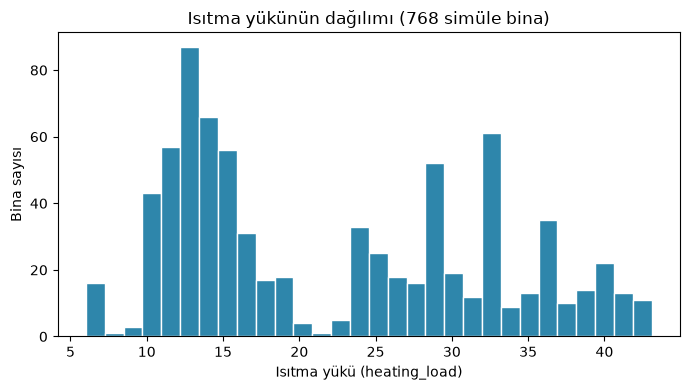

In [9]:
fig, ax = plt.subplots(figsize=(7, 4))
ax.hist(df['heating_load'], bins=30, color='#2E86AB', edgecolor='white')
ax.set_title('Isıtma yükünün dağılımı (768 simüle bina)')
ax.set_xlabel('Isıtma yükü (heating_load)'); ax.set_ylabel('Bina sayısı')
fig.tight_layout(); fig.savefig(FIG_DIR / '01_hedef_dagilimi.png', dpi=150); plt.show()

**Yorum:** Dağılım tek bir tepeli değildir; iki ayrı küme görülür. Aşağıdaki grafik, bu iki kümenin bina yüksekliğiyle ilişkili olduğunu gösterir.

### 5.4 Grafik 2 — Göreli kompaktlık ve ısıtma yükü (renk: bina yüksekliği)

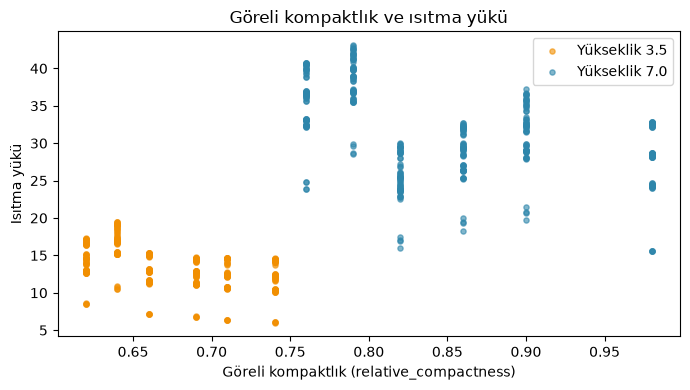

In [10]:
fig, ax = plt.subplots(figsize=(7, 4))
for h, color in [(3.5, '#F18F01'), (7.0, '#2E86AB')]:
    part = df[df.overall_height == h]
    ax.scatter(part.relative_compactness, part.heating_load, s=14, alpha=0.6, color=color, label=f'Yükseklik {h}')
ax.set_title('Göreli kompaktlık ve ısıtma yükü')
ax.set_xlabel('Göreli kompaktlık (relative_compactness)'); ax.set_ylabel('Isıtma yükü'); ax.legend()
fig.tight_layout(); fig.savefig(FIG_DIR / '02_kompaktlik_isitma.png', dpi=150); plt.show()

**Yorum:** Yüksek (7.0) binalar sistematik olarak daha yüksek ısıtma yüküne sahiptir. Aynı yükseklikteki binalar arasında da kompaktlık arttıkça yük artmaktadır. İlişki tam doğrusal değildir; bu durum doğrusal modelin sınırlarından biri olacaktır.

### 5.5 Grafik 3 — Cam alanına göre ortalama ısıtma yükü

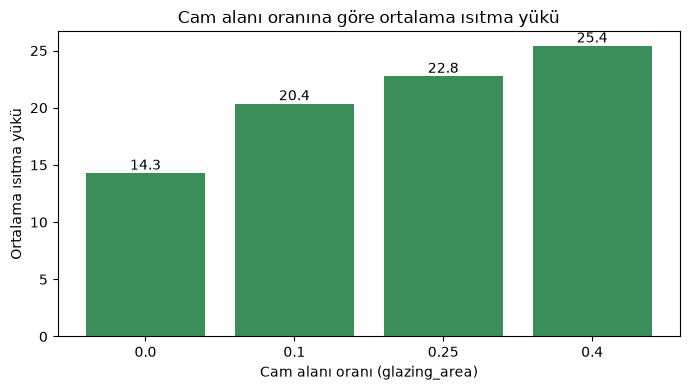

In [11]:
fig, ax = plt.subplots(figsize=(7, 4))
ax.bar(by_glazing.index.astype(str), by_glazing['mean'], color='#3B8E5A')
for i, v in enumerate(by_glazing['mean']):
    ax.text(i, v + 0.3, f'{v:.1f}', ha='center')
ax.set_title('Cam alanı oranına göre ortalama ısıtma yükü')
ax.set_xlabel('Cam alanı oranı (glazing_area)'); ax.set_ylabel('Ortalama ısıtma yükü')
fig.tight_layout(); fig.savefig(FIG_DIR / '03_cam_alani_ortalama.png', dpi=150); plt.show()

### 5.6 Grafik 4 — Özelliklerin hedefle korelasyonu

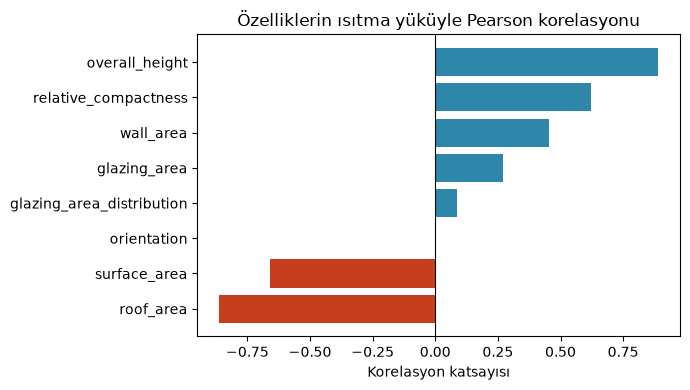

roof_area                   -0.862
surface_area                -0.658
orientation                 -0.003
glazing_area_distribution    0.087
glazing_area                 0.270
wall_area                    0.456
relative_compactness         0.622
overall_height               0.889
Name: heating_load, dtype: float64


In [12]:
features = list(COLUMNS.values())[:8]
corr = df[features + ['heating_load']].corr()['heating_load'].drop('heating_load').sort_values()
fig, ax = plt.subplots(figsize=(7, 4))
ax.barh(corr.index, corr.values, color=['#C73E1D' if v < 0 else '#2E86AB' for v in corr.values])
ax.set_title('Özelliklerin ısıtma yüküyle Pearson korelasyonu'); ax.set_xlabel('Korelasyon katsayısı')
ax.axvline(0, color='black', linewidth=0.8)
fig.tight_layout(); fig.savefig(FIG_DIR / '04_korelasyon.png', dpi=150); plt.show()
print(corr.round(3))

### 5.7 Keşif bulguları
Bulgular aşağıdaki hücrede doğrudan veriden hesaplanır.

In [13]:
h = df.groupby('overall_height')['heating_load'].mean()
g = df.groupby('glazing_area')['heating_load'].mean()
o = df.groupby('orientation')['heating_load'].mean()
findings = {
    'yukseklik_ortalama_3_5': round(float(h.loc[3.5]), 2),
    'yukseklik_ortalama_7_0': round(float(h.loc[7.0]), 2),
    'cam_0_ortalama': round(float(g.loc[0.0]), 2),
    'cam_0_40_ortalama': round(float(g.loc[0.4]), 2),
    'yon_ortalama_fark': round(float(o.max() - o.min()), 3),
    'en_guclu_pozitif_korelasyon': [corr.idxmax(), round(float(corr.max()), 3)],
    'en_guclu_negatif_korelasyon': [corr.idxmin(), round(float(corr.min()), 3)],
}
print(f"1) Yükseklik belirleyici: 3.5 m binalarda ortalama {findings['yukseklik_ortalama_3_5']}, 7.0 m binalarda {findings['yukseklik_ortalama_7_0']}.")
print(f"2) Cam alanı arttıkça yük artıyor: cam yokken ortalama {findings['cam_0_ortalama']}, 0.40 oranında {findings['cam_0_40_ortalama']}.")
print(f"3) Yönün etkisi çok küçük: yönlere göre ortalamalar arasındaki en büyük fark {findings['yon_ortalama_fark']}.")
print(f"4) En güçlü pozitif ilişki: {findings['en_guclu_pozitif_korelasyon'][0]} (r = {findings['en_guclu_pozitif_korelasyon'][1]}); "
      f"en güçlü negatif ilişki: {findings['en_guclu_negatif_korelasyon'][0]} (r = {findings['en_guclu_negatif_korelasyon'][1]}).")

1) Yükseklik belirleyici: 3.5 m binalarda ortalama 13.34, 7.0 m binalarda 31.28.
2) Cam alanı arttıkça yük artıyor: cam yokken ortalama 14.29, 0.40 oranında 25.41.
3) Yönün etkisi çok küçük: yönlere göre ortalamalar arasındaki en büyük fark 0.121.
4) En güçlü pozitif ilişki: overall_height (r = 0.889); en güçlü negatif ilişki: roof_area (r = -0.862).


## 6. Model kurma ve eğitme

**Model seçim gerekçesi:** Hedef sayısal olduğu için regresyon gerekir. `LinearRegression` yorumlanabilir, hızlı ve eğitimdeki yöntemle uyumlu bir başlangıç modelidir. Her özelliğin tahmine etkisi bir katsayıyla görülebilir.

- `cooling_load`, ısıtma yüküyle birlikte simülasyonun bir çıktısıdır. Girdi olarak kullanılırsa hedef sızıntısı olur; bu yüzden modele alınmaz.
- Doğrusal regresyonun tahminleri özellik ölçeğinden etkilenmez; bu nedenle ölçeklendirme uygulanmadı. Böylece test verisinden bilgi sızması riski de oluşmaz.

In [14]:
X = df[features]
y = df['heating_load']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print('X_train:', X_train.shape, ' X_test:', X_test.shape, ' y_train:', y_train.shape, ' y_test:', y_test.shape)
print('Eğitim ve test indeksleri kesişiyor mu?', bool(set(X_train.index) & set(X_test.index)))
model = LinearRegression()
model.fit(X_train, y_train)
print('Model eğitildi.')

X_train: (614, 8)  X_test: (154, 8)  y_train: (614,)  y_test: (154,)
Eğitim ve test indeksleri kesişiyor mu? False
Model eğitildi.


## 7. Tahmin ve değerlendirme
MAE, RMSE ve R² metrikleri eğitim ve test kümelerinde ayrı ayrı hesaplanır. `model.score` R² değerini verir.

In [15]:
def metrics(y_true, y_pred):
    return {'MAE': float(mean_absolute_error(y_true, y_pred)),
            'RMSE': float(np.sqrt(mean_squared_error(y_true, y_pred))),
            'R2': float(r2_score(y_true, y_pred))}

pred_train, pred_test = model.predict(X_train), model.predict(X_test)
results = pd.DataFrame({'Eğitim': metrics(y_train, pred_train), 'Test': metrics(y_test, pred_test)})
print(results.round(4))
print(f"\nmodel.score(X_test, y_test) = {model.score(X_test, y_test):.4f}")
coef = pd.Series(model.coef_, index=features)
print('\nKatsayılar:'); print(coef.round(4)); print('Sabit terim:', round(float(model.intercept_), 4))

      Eğitim    Test
MAE   2.0414  2.1821
RMSE  2.8931  3.0254
R2    0.9171  0.9122

model.score(X_test, y_test) = 0.9122

Katsayılar:
relative_compactness        -61.8734
surface_area                 -0.0601
wall_area                     0.0376
roof_area                    -0.0488
overall_height                4.1237
orientation                  -0.0324
glazing_area                 20.1432
glazing_area_distribution     0.2111
dtype: float64
Sabit terim: 79.727


### Grafik 5 — Gerçek ve tahmin edilen değerler (test kümesi)

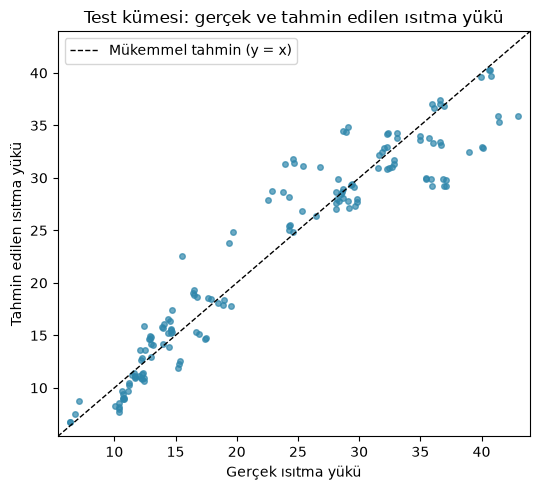

In [16]:
fig, ax = plt.subplots(figsize=(5.5, 5))
ax.scatter(y_test, pred_test, s=16, alpha=0.7, color='#2E86AB')
lims = [min(y_test.min(), pred_test.min()) - 1, max(y_test.max(), pred_test.max()) + 1]
ax.plot(lims, lims, 'k--', linewidth=1, label='Mükemmel tahmin (y = x)')
ax.set_xlim(lims); ax.set_ylim(lims)
ax.set_title('Test kümesi: gerçek ve tahmin edilen ısıtma yükü')
ax.set_xlabel('Gerçek ısıtma yükü'); ax.set_ylabel('Tahmin edilen ısıtma yükü'); ax.legend()
fig.tight_layout(); fig.savefig(FIG_DIR / '05_gercek_tahmin.png', dpi=150); plt.show()

### Grafik 6 — Hata (artık) dağılımı

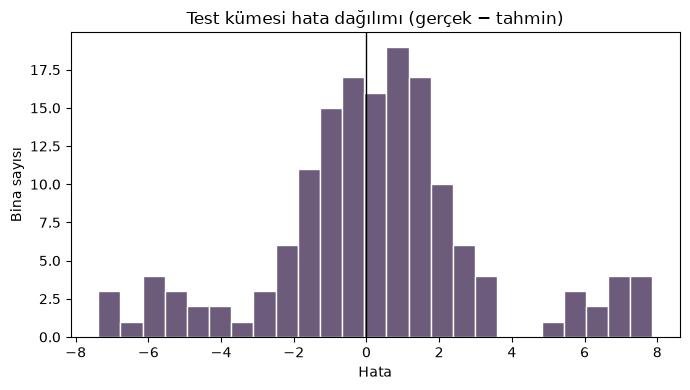

Mutlak hata > 5 olan test örneği sayısı: 25 / 154
Yüksekliğe göre ortalama mutlak hata:
yukseklik
3.5    1.439
7.0    2.834
Name: abs_hata, dtype: float64

En büyük 5 hata:
     gercek  tahmin  abs_hata  yukseklik
65    37.12   29.26      7.86        7.0
66    36.90   29.22      7.68        7.0
23    23.93   31.31      7.38        7.0
211   37.10   29.83      7.27        7.0
451   40.12   32.85      7.27        7.0


In [17]:
residuals = y_test - pred_test
fig, ax = plt.subplots(figsize=(7, 4))
ax.hist(residuals, bins=25, color='#6C5B7B', edgecolor='white')
ax.axvline(0, color='black', linewidth=1)
ax.set_title('Test kümesi hata dağılımı (gerçek − tahmin)')
ax.set_xlabel('Hata'); ax.set_ylabel('Bina sayısı')
fig.tight_layout(); fig.savefig(FIG_DIR / '06_hata_dagilimi.png', dpi=150); plt.show()
err = pd.DataFrame({'gercek': y_test, 'tahmin': pred_test, 'abs_hata': residuals.abs(), 'yukseklik': X_test.overall_height})
print('Mutlak hata > 5 olan test örneği sayısı:', int((err.abs_hata > 5).sum()), '/', len(err))
print('Yüksekliğe göre ortalama mutlak hata:'); print(err.groupby('yukseklik')['abs_hata'].mean().round(3))
print('\nEn büyük 5 hata:'); print(err.sort_values('abs_hata', ascending=False).head().round(2))

## 8. Yeni örnekler için tahmin

Üç yeni bina tanımlanır. Geometri değerleri (X1–X5) veri setindeki gerçek bina tiplerinden alınır. Bu değerler birbirine bağlıdır; rastgele bir kombinasyon fiziksel olarak tutarsız olabilir.

Cam alanı oranları (0.05, 0.15, 0.30) veri setinde **bulunmayan** ara değerlerdir. Bu nedenle bu girdiler modelin daha önce görmediği yeni örneklerdir.

In [18]:
shapes = df[['relative_compactness', 'surface_area', 'wall_area', 'roof_area', 'overall_height']].drop_duplicates() \
    .sort_values('relative_compactness', ascending=False).reset_index(drop=True)
new = pd.DataFrame([
    {**shapes.loc[0].to_dict(), 'orientation': 2, 'glazing_area': 0.05, 'glazing_area_distribution': 1},
    {**shapes.loc[5].to_dict(), 'orientation': 3, 'glazing_area': 0.15, 'glazing_area_distribution': 2},
    {**shapes.loc[11].to_dict(), 'orientation': 4, 'glazing_area': 0.30, 'glazing_area_distribution': 5},
])[features]
assert not new.merge(df[features], how='inner').shape[0], 'yeni örnekler veri setinde olmamalı'
new['tahmin_isitma_yuku'] = model.predict(new[features]).round(2)
new

,relative_compactness,surface_area,wall_area,roof_area,overall_height,orientation,glazing_area,glazing_area_distribution,tahmin_isitma_yuku
0,0.98,514.5,294.0,110.25,7.0,2,0.05,1,23.84
1,0.76,661.5,416.5,122.50,7.0,3,0.15,2,34.82
2,0.62,808.5,367.5,220.50,3.5,4,0.30,5,17.21


## 9. Değerlendirme notu

- **Güvenilirlik:** Eğitim ve test metrikleri birbirine yakınsa aşırı öğrenme belirtisi yoktur; değerler yukarıdaki tabloda verilmiştir.
- **Sınırlar:** Doğrusal model, yükseklik ve kompaktlığın oluşturduğu doğrusal olmayan yapıyı ve iki kümeli dağılımı tam yakalayamaz. Bu durum hata grafiğinde görülür.
- **Katsayılar:** Geometri değişkenleri (X1–X4) birbirine bağlı olduğu için katsayılar tek tek "etki büyüklüğü" olarak yorumlanmamalıdır.
- **Veri:** Veri simülasyondan üretilmiştir ve yalnızca 12 bina şeklini kapsar. Gerçek binalara ve farklı iklimlere genelleme yapılamaz.
- **İyileştirme önerileri:**
  - Yön ve cam dağılım kodlarını one-hot kodlamak.
  - Etkileşim terimleri eklemek.
  - Karar ağacı veya rastgele orman gibi doğrusal olmayan modelleri denemek.
  - Çapraz doğrulama yapmak.

In [19]:
summary = {'shape': list(df.shape), 'missing_total': int(df.isnull().sum().sum()),
           'n_train': int(len(X_train)), 'n_test': int(len(X_test)),
           'train_metrics': metrics(y_train, pred_train), 'test_metrics': metrics(y_test, pred_test),
           'model_score_test_R2': float(model.score(X_test, y_test)), 'findings': findings,
           'new_predictions': new['tahmin_isitma_yuku'].tolist()}
out = FIG_DIR.parent / 'notebook_metrics.json'
out.write_text(json.dumps(summary, indent=2, ensure_ascii=False), encoding='utf-8')
print('Kaydedildi:', out)
print(json.dumps({k: summary[k] for k in ('n_train', 'n_test', 'test_metrics')}, indent=2))

Kaydedildi: reports\notebook_metrics.json
{
  "n_train": 614,
  "n_test": 154,
  "test_metrics": {
    "MAE": 2.1820729961538934,
    "RMSE": 3.0254268535103717,
    "R2": 0.9121846294352439
  }
}
